# ⚛️ QuantumShield — Quantum Kernel Network Intrusion Detection

**Interstate Quantum Hackathon Fall 2026 · QML Track · Two-person team**

**Research question:** Does a four-qubit *entangling* quantum feature map help distinguish benign from malicious network traffic, relative to a non-entangling map and a classical RBF SVM?

This notebook builds on the organizers' `QML_1_Lecture.ipynb`, particularly Parts 2–5. It uses **Qiskit Machine Learning** and a **local statevector simulator**, so no Google account or quantum computer is required.

**Plan:** Load NSL-KDD → preprocess 4 traffic features → tune quantum encoding bandwidth on training data → fit classical and quantum classifiers → measure honest held-out performance → generate report figures.

> **Scope & limitations:** A small, class-balanced subsample from a legacy benchmark is a *methodology demonstration*, not a working enterprise intrusion-detection system. No claim of quantum speedup is made. Simulator runtime is classical runtime.

In [1]:
# Hackathon requirement: first command installs packages needed to run from a clean notebook.
# When already installed in your qml-env, this should finish quickly.
%pip install -q "qiskit>=2.0,<3" "qiskit-machine-learning>=0.9,<1" "scikit-learn>=1.5,<2" "numpy>=2,<3" "pandas>=2,<3" "matplotlib>=3.8,<4" "ipykernel"

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and reproducible experiment settings

The sample sizes are controlled by `TRAIN_PER_CLASS`, `TEST_PER_CLASS`, and `SEED` in the next cell. The current configuration uses **80 benign + 80 attack training records** (160 total) and **100 benign + 100 attack test records** (200 total). For comparisons, keep the same test sample and record all settings.

We evaluate a deliberately balanced, small subset of a legacy dataset. It is a quantum machine-learning research demonstration, not a deployable intrusion detector.

In [2]:
from pathlib import Path
from urllib.request import urlretrieve
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay,
)
from qiskit.circuit.library import zz_feature_map, z_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC

SEED = 42
TRAIN_PER_CLASS = 80
TEST_PER_CLASS = 100
REPS = 2
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
print("QuantumShield environment ready.")

QuantumShield environment ready.


## 2. Download real labeled cybersecurity data

**Source:** [NSL-KDD GitHub mirror](https://github.com/Jehuty4949/NSL_KDD), containing public legacy intrusion-detection benchmark files.

- `KDDTrain+_20Percent.txt` is a training-only subset.
- `KDDTest+.txt` is a separate test split; we never use it to tune parameters.
- Each record has **41 features**, then an attack name (`normal` or a named attack), then a difficulty field.

The two files are downloaded on the first run and cached locally. **Internet access is needed only for this download.** If a download fails, open the URL displayed in the error message and save that file to the notebook's `data/` folder.

In [3]:
DATA_URLS = {
    "KDDTrain+_20Percent.txt": "https://raw.githubusercontent.com/Jehuty4949/NSL_KDD/master/KDDTrain%2B_20Percent.txt",
    "KDDTest+.txt": "https://raw.githubusercontent.com/Jehuty4949/NSL_KDD/master/KDDTest%2B.txt",
}
for name, url in DATA_URLS.items():
    target = DATA_DIR / name
    if not target.exists():
        print(f"Downloading {name} ...")
        try:
            urlretrieve(url, target)
        except Exception as exc:
            raise RuntimeError(f"Could not download {name}. Manually download {url} into {DATA_DIR.resolve()}") from exc
    else:
        print(f"Found {target}")

raw_train = pd.read_csv(DATA_DIR / "KDDTrain+_20Percent.txt", header=None)
raw_test  = pd.read_csv(DATA_DIR / "KDDTest+.txt", header=None)
assert raw_train.shape[1] == raw_test.shape[1] == 43, "Expected 43 NSL-KDD fields"
print("Official source rows — train:", len(raw_train), "test:", len(raw_test))
print("Example attack labels:", raw_train.iloc[:,41].value_counts().head().to_dict())

Found data/KDDTrain+_20Percent.txt
Found data/KDDTest+.txt
Official source rows — train: 25192 test: 22544
Example attack labels: {'normal': 13449, 'neptune': 8282, 'ipsweep': 710, 'satan': 691, 'portsweep': 587}


## 3. Select four network features and balanced samples

Our four inputs are numerical fields with known positions in NSL-KDD:

| Input | NSL-KDD column (zero-based) | Meaning |
|---|---:|---|
| `src_bytes` | 4 | Bytes from source to destination |
| `dst_bytes` | 5 | Bytes from destination to source |
| `count` | 22 | Recent connections to the same destination host |
| `srv_serror_rate` | 25 | SYN-error rate for the same service |

The true label is in column **41**: `normal` means benign; everything else is an attack. The difficulty field in column 42 is **never used** as a predictor.

We apply `log1p` to skewed count/byte columns, then fit MinMax scaling **only on training examples**. This avoids leaking test information into the model.

In [4]:
FEATURE_COLUMNS = {"src_bytes": 4, "dst_bytes": 5, "count": 22, "srv_serror_rate": 25}
FEATURE_NAMES = list(FEATURE_COLUMNS)

def prepare_frame(raw):
    out = pd.DataFrame({name: pd.to_numeric(raw.iloc[:, idx], errors="raise")
                        for name, idx in FEATURE_COLUMNS.items()})
    out["is_attack"] = (raw.iloc[:, 41].astype(str).str.strip() != "normal").astype(int).to_numpy()
    return out.dropna().reset_index(drop=True)

def balanced_subset(df, per_class, seed):
    pieces = []
    for label in (0, 1):
        subset = df.loc[df["is_attack"] == label]
        if len(subset) < per_class:
            raise ValueError(f"Not enough class-{label} records: {len(subset)}")
        pieces.append(subset.sample(n=per_class, random_state=seed))
    return pd.concat(pieces, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)

train_df = balanced_subset(prepare_frame(raw_train), TRAIN_PER_CLASS, SEED)
test_df  = balanced_subset(prepare_frame(raw_test), TEST_PER_CLASS, SEED + 1)

X_train_raw = train_df[FEATURE_NAMES].to_numpy(dtype=float)
X_test_raw  = test_df[FEATURE_NAMES].to_numpy(dtype=float)
y_train = train_df["is_attack"].to_numpy()
y_test  = test_df["is_attack"].to_numpy()

# Log-scale the highly skewed nonnegative features; keep the error rate unchanged.
for index in (0, 1, 2):
    X_train_raw[:, index] = np.log1p(np.clip(X_train_raw[:, index], 0, None))
    X_test_raw[:, index] = np.log1p(np.clip(X_test_raw[:, index], 0, None))

scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train = scaler.fit_transform(X_train_raw)
X_test = np.clip(scaler.transform(X_test_raw), 0, np.pi)

print("Train shape:", X_train.shape, "/ labels:", np.bincount(y_train))
print("Test shape:", X_test.shape, "/ labels:", np.bincount(y_test))
print("Sample encoded data [0, pi]:", np.round(X_train[0], 3))
assert X_train.shape[1] == 4 and X_test.shape[1] == 4
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

Train shape: (160, 4) / labels: [80 80]
Test shape: (200, 4) / labels: [100 100]
Sample encoded data [0, pi]: [0.    0.    2.658 3.142]


## 4. Training-only cross-validation: independently tune classical and quantum models

The **classical RBF SVM** gets its own penalty `C` and kernel width `gamma` search. The **quantum Z** and **quantum ZZ** feature maps each get their own bandwidth `lambda` and penalty `C` search.

For every 3-fold cross-validation split, `MinMaxScaler` is **fitted only on that fold's training records** and then applied to its validation records. We do not inspect the separate held-out test set during tuning. Quantum kernels are evaluated with a **local exact statevector simulator**, not quantum hardware.

Note: This expanded tuning is slower than the starter notebook; it requires several quantum kernel calculations. The selected parameters can differ from prior runs, so do not reuse old accuracy numbers when reporting these new experiments.

In [5]:
# Fair comparison: fit scaling inside each CV fold, not on the full training sample.
LAMBDA_CANDIDATES = (0.25, 0.50, 1.0)
C_CANDIDATES = (0.1, 1.0, 10.0)
GAMMA_CANDIDATES = ("scale", 0.1, 1.0)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
fold_data = []
for train_idx, valid_idx in cv.split(X_train_raw, y_train):
    fold_scaler = MinMaxScaler(feature_range=(0, np.pi))
    X_fold_train = fold_scaler.fit_transform(X_train_raw[train_idx])
    X_fold_valid = np.clip(fold_scaler.transform(X_train_raw[valid_idx]), 0, np.pi)
    fold_data.append((X_fold_train, X_fold_valid, y_train[train_idx], y_train[valid_idx]))

# Tune classical RBF SVM using ONLY these training folds.
classical_cv_rows = []
for C in C_CANDIDATES:
    for gamma in GAMMA_CANDIDATES:
        scores = []
        for X_tr, X_val, y_tr, y_val in fold_data:
            clf = SVC(kernel="rbf", C=C, gamma=gamma).fit(X_tr, y_tr)
            scores.append(balanced_accuracy_score(y_val, clf.predict(X_val)))
        classical_cv_rows.append({
            "C": C, "gamma": gamma,
            "cv_balanced_accuracy": float(np.mean(scores)),
            "cv_std": float(np.std(scores)),
        })
classical_cv_results = pd.DataFrame(classical_cv_rows)
best_classical_row = classical_cv_results.sort_values(
    ["cv_balanced_accuracy", "C"], ascending=[False, True]
).iloc[0]
best_classical_params = {
    "C": float(best_classical_row["C"]),
    "gamma": best_classical_row["gamma"],
}
classical_cv_results.to_csv(RESULTS_DIR / "classical_cv.csv", index=False)

# Independently tune BOTH quantum feature maps.
quantum_feature_maps = {
    "Quantum Z QSVC": z_feature_map(feature_dimension=4, reps=REPS),
    "Quantum ZZ QSVC": zz_feature_map(feature_dimension=4, reps=REPS, entanglement="linear"),
}
quantum_cv_rows = []
start = time.perf_counter()
for model_name, feature_map in quantum_feature_maps.items():
    kernel = FidelityStatevectorKernel(feature_map=feature_map)
    for lam in LAMBDA_CANDIDATES:
        # Kernel matrices are calculated once per fold and reused across C values.
        fold_kernels = []
        for X_tr, X_val, y_tr, y_val in fold_data:
            K_tr = kernel.evaluate(X_tr * lam)
            K_val = kernel.evaluate(X_val * lam, X_tr * lam)
            fold_kernels.append((K_tr, K_val, y_tr, y_val))
        for C in C_CANDIDATES:
            scores = []
            for K_tr, K_val, y_tr, y_val in fold_kernels:
                clf = SVC(kernel="precomputed", C=C).fit(K_tr, y_tr)
                scores.append(balanced_accuracy_score(y_val, clf.predict(K_val)))
            quantum_cv_rows.append({
                "model": model_name, "lambda": lam, "C": C,
                "cv_balanced_accuracy": float(np.mean(scores)),
                "cv_std": float(np.std(scores)),
            })

quantum_cv_results = pd.DataFrame(quantum_cv_rows)
best_quantum_params = {}
for model_name in quantum_feature_maps:
    best = quantum_cv_results.loc[quantum_cv_results["model"] == model_name].sort_values(
        ["cv_balanced_accuracy", "lambda", "C"],
        ascending=[False, True, True]
    ).iloc[0]
    best_quantum_params[model_name] = {"lambda": float(best["lambda"]), "C": float(best["C"])}

quantum_cv_results.to_csv(RESULTS_DIR / "bandwidth_cv.csv", index=False)
print("Best classical settings:", best_classical_params)
print("Best quantum settings:", best_quantum_params)
print(f"Quantum cross-validation completed in {time.perf_counter() - start:.1f} seconds")
display(classical_cv_results.sort_values("cv_balanced_accuracy", ascending=False).head(5))
display(quantum_cv_results.sort_values("cv_balanced_accuracy", ascending=False).groupby("model").head(3))

Best classical settings: {'C': 10.0, 'gamma': 'scale'}
Best quantum settings: {'Quantum Z QSVC': {'lambda': 1.0, 'C': 10.0}, 'Quantum ZZ QSVC': {'lambda': 0.5, 'C': 1.0}}
Quantum cross-validation completed in 7.3 seconds


,C,gamma,cv_balanced_accuracy,cv_std
8,10.0,1.0,0.950380,0.038322
6,10.0,scale,0.950380,0.038322
5,1.0,1.0,0.944207,0.040225
7,10.0,0.1,0.931149,0.017314
0,0.1,scale,0.906458,0.030270


,model,lambda,C,cv_balanced_accuracy,cv_std
8,Quantum Z QSVC,1.00,10.0,0.956315,0.008394
13,Quantum ZZ QSVC,0.50,1.0,0.956078,0.022720
14,Quantum ZZ QSVC,0.50,10.0,0.949905,0.022913
11,Quantum ZZ QSVC,0.25,10.0,0.943970,0.029950
5,Quantum Z QSVC,0.50,10.0,0.937797,0.031384
7,Quantum Z QSVC,1.00,1.0,0.931387,0.031211


## 5. Fit three classifiers with their **independently selected** settings

- **Classical RBF SVM:** penalty `C` and RBF width `gamma` selected by CV.
- **Quantum ZZ QSVC:** entangling feature map, independently chosen bandwidth `lambda` and `C`.
- **Quantum Z QSVC:** no entangling feature-map gates, independently chosen bandwidth `lambda` and `C`.

After choosing all settings with **training-only cross-validation**, we fit each model on the full 160-row training subset and score the **separate 200-row test subset**. The quantum models use exact statevector kernel simulation, not quantum hardware.

In [6]:
models = {}
preds = {}
fit_seconds = {}

# 1. Tuned classical RBF SVM
start = time.perf_counter()
models["Classical RBF SVM"] = SVC(
    kernel="rbf", **best_classical_params
).fit(X_train, y_train)
fit_seconds["Classical RBF SVM"] = time.perf_counter() - start
preds["Classical RBF SVM"] = models["Classical RBF SVM"].predict(X_test)

# 2. Independently tuned entangling ZZ quantum kernel SVM
fmap_zz = quantum_feature_maps["Quantum ZZ QSVC"]
qkernel_zz = FidelityStatevectorKernel(feature_map=fmap_zz)
params_zz = best_quantum_params["Quantum ZZ QSVC"]
start = time.perf_counter()
models["Quantum ZZ QSVC"] = QSVC(
    quantum_kernel=qkernel_zz, C=params_zz["C"]
).fit(X_train * params_zz["lambda"], y_train)
fit_seconds["Quantum ZZ QSVC"] = time.perf_counter() - start
preds["Quantum ZZ QSVC"] = models["Quantum ZZ QSVC"].predict(X_test * params_zz["lambda"])

# 3. Independently tuned non-entangling Z quantum kernel SVM
fmap_z = quantum_feature_maps["Quantum Z QSVC"]
qkernel_z = FidelityStatevectorKernel(feature_map=fmap_z)
params_z = best_quantum_params["Quantum Z QSVC"]
start = time.perf_counter()
models["Quantum Z QSVC"] = QSVC(
    quantum_kernel=qkernel_z, C=params_z["C"]
).fit(X_train * params_z["lambda"], y_train)
fit_seconds["Quantum Z QSVC"] = time.perf_counter() - start
preds["Quantum Z QSVC"] = models["Quantum Z QSVC"].predict(X_test * params_z["lambda"])

print("Finished training and predicting with all three independently tuned models.")
print("Note: fit_seconds excludes CV tuning and test prediction time.")

Finished training and predicting with all three independently tuned models.
Note: fit_seconds excludes CV tuning and test prediction time.


## 6. Held-out results (do not assume a quantum win)

**Attack = positive class (1).** For an intrusion detector, pay particular attention to attack recall (false negatives) and false-positive rate (benign connections wrongly flagged).

This run evaluates **200 separate test observations**, half benign and half malicious. The sample is small and deliberately class-balanced, so it does not represent normal deployment traffic. We have already inspected this test subset during earlier explorations: treat these results as **exploratory**, not a fresh unbiased final test of a selected model.

,model,accuracy,balanced_accuracy,precision_attack,recall_attack,f1_attack,false_positive_rate,false_negatives,fit_seconds
0,Classical RBF SVM,0.805,0.805,0.942,0.65,0.769,0.04,35,0.001
1,Quantum ZZ QSVC,0.760,0.760,0.919,0.57,0.704,0.05,43,0.419
2,Quantum Z QSVC,0.780,0.780,0.967,0.58,0.725,0.02,42,0.285


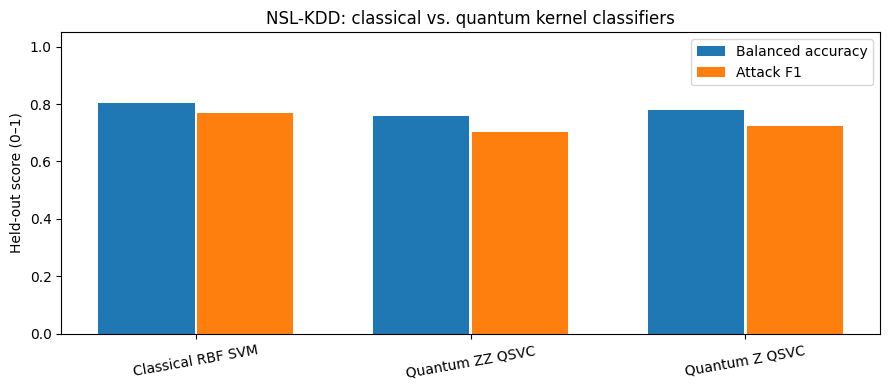

In [7]:
rows = []
for name, y_pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0,1]).ravel()
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "precision_attack": precision_score(y_test, y_pred, zero_division=0),
        "recall_attack": recall_score(y_test, y_pred, zero_division=0),
        "f1_attack": f1_score(y_test, y_pred, zero_division=0),
        "false_positive_rate": fp / (fp + tn),
        "false_negatives": int(fn),
        "fit_seconds": fit_seconds[name],
    })
metrics = pd.DataFrame(rows)
display(metrics.round(3))
metrics.to_csv(RESULTS_DIR / "metrics.csv", index=False)

fig, ax = plt.subplots(figsize=(9,4))
xs = np.arange(len(metrics))
ax.bar(xs - .18, metrics["balanced_accuracy"], width=.35, label="Balanced accuracy")
ax.bar(xs + .18, metrics["f1_attack"], width=.35, label="Attack F1")
ax.set_xticks(xs, metrics["model"], rotation=10)
ax.set_ylabel("Held-out score (0–1)")
ax.set_ylim(0, 1.05)
ax.set_title("NSL-KDD: classical vs. quantum kernel classifiers")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "model_comparison.png", dpi=170)
plt.show()

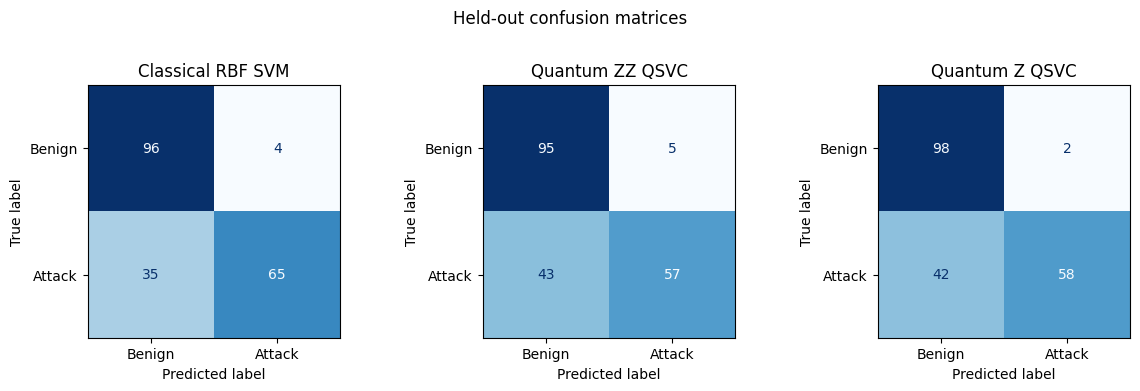

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12,3.7))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0,1],
        display_labels=["Benign", "Attack"],
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
fig.suptitle("Held-out confusion matrices", y=1.03)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=170, bbox_inches="tight")
plt.show()

## 7. Visualize the quantum representation

The kernel matrix entry $K_{ij}=|\langle\phi(x_i)|\phi(x_j)\rangle|^2$ measures the overlap of encoded states. We plot matrices sorted by the **training labels**. If the quantum representation is useful, we may see stronger within-class similarity than between-class similarity; this pattern is not guaranteed.

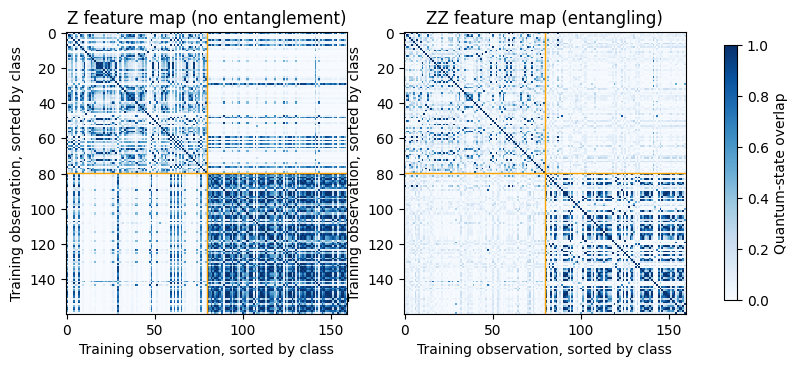

ZZ circuit:
    ┌───┐┌───────────┐                                          ┌───┐»
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«            ┌───────────┐                                                    »
«0: ─────────┤ P(2*x[0]) ├────────────────────────────────────────────────────»
«            └───────────┘               ┌───┐         ┌───────────┐          »
«1: ──────────────────────────────────■──┤ H ├─────────┤ P(2*x[1]) ├──────────»
«   ┌──────────────────────────────┐┌

In [9]:
order = np.argsort(y_train, kind="stable")
# Each feature map is visualized using its OWN independently selected bandwidth.
K_zz = qkernel_zz.evaluate(X_train * params_zz["lambda"])
K_z = qkernel_z.evaluate(X_train * params_z["lambda"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, K, title in zip(
    axes, (K_z, K_zz),
    ("Z feature map (no entanglement)", "ZZ feature map (entangling)")
):
    im = ax.imshow(K[np.ix_(order, order)], vmin=0, vmax=1, cmap="Blues", interpolation="nearest")
    ax.set_xlabel("Training observation, sorted by class")
    ax.set_ylabel("Training observation, sorted by class")
    ax.set_title(title)
    ax.axhline(TRAIN_PER_CLASS - 0.5, color="orange", lw=1)
    ax.axvline(TRAIN_PER_CLASS - 0.5, color="orange", lw=1)
fig.colorbar(im, ax=axes, label="Quantum-state overlap", shrink=0.77)
fig.savefig(RESULTS_DIR / "kernel_comparison.png", dpi=170, bbox_inches="tight")
plt.show()
print("ZZ circuit:\n", fmap_zz.draw(output="text"))

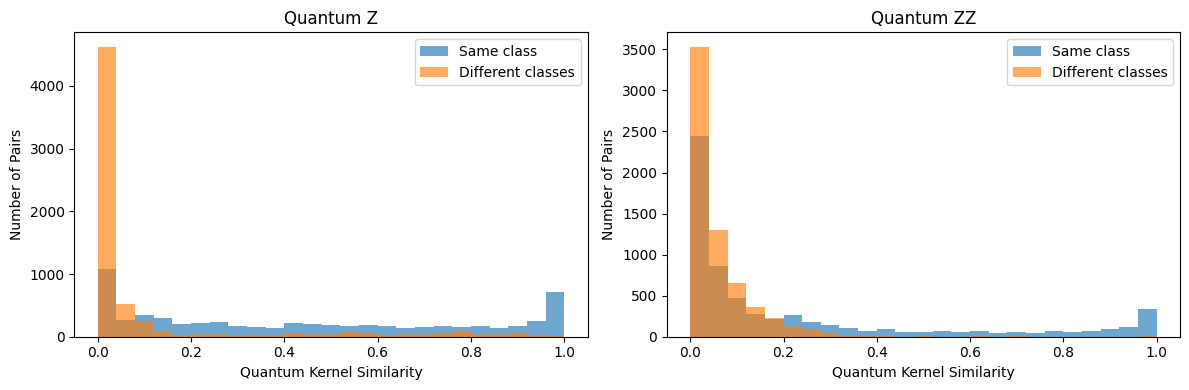

,feature_map,within_class_similarity,between_class_similarity,similarity_gap
0,Quantum Z,0.4404,0.1023,0.3382
1,Quantum ZZ,0.2244,0.0586,0.1658


In [10]:
# QuantumShield: Quantum Kernel Similarity Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get unique pairs of training observations
i, j = np.triu_indices(len(y_train), k=1)

# Check whether each pair belongs to the same class
same_class = y_train[i] == y_train[j]

results = []

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, K) in zip(
    axes,
    [
        ("Quantum Z", K_z),
        ("Quantum ZZ", K_zz)
    ]
):
    within = K[i[same_class], j[same_class]]
    between = K[i[~same_class], j[~same_class]]

    within_mean = np.mean(within)
    between_mean = np.mean(between)

    separation = within_mean - between_mean

    results.append({
        "feature_map": name,
        "within_class_similarity": within_mean,
        "between_class_similarity": between_mean,
        "similarity_gap": separation
    })

    ax.hist(
        within,
        bins=25,
        alpha=0.65,
        label="Same class"
    )

    ax.hist(
        between,
        bins=25,
        alpha=0.65,
        label="Different classes"
    )

    ax.set_title(name)
    ax.set_xlabel("Quantum Kernel Similarity")
    ax.set_ylabel("Number of Pairs")
    ax.legend()

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "quantum_similarity_analysis.png",
    dpi=170
)

plt.show()

similarity_results = pd.DataFrame(results)

display(similarity_results.round(4))

similarity_results.to_csv(
    RESULTS_DIR / "quantum_similarity_metrics.csv",
    index=False
)

## 8. Demonstration: classify held-out historical observations

This is a safe replay of labeled historical data, **not** live packet capture. It does not generate, launch, or block network attacks.

In [11]:
demo = pd.DataFrame({
    "record": np.arange(1, 9),
    "actual": np.where(y_test[:8] == 1, "Attack", "Benign"),
    "classical": np.where(preds["Classical RBF SVM"][:8] == 1, "Attack", "Benign"),
    "quantum_ZZ": np.where(preds["Quantum ZZ QSVC"][:8] == 1, "Attack", "Benign"),
})
display(demo)
demo.to_csv(RESULTS_DIR / "demo_predictions.csv", index=False)

,record,actual,classical,quantum_ZZ
0,1,Benign,Benign,Benign
1,2,Benign,Benign,Benign
2,3,Benign,Benign,Benign
3,4,Benign,Benign,Benign
4,5,Benign,Benign,Benign
5,6,Attack,Benign,Benign
6,7,Attack,Attack,Attack
7,8,Benign,Benign,Benign


In [12]:
# Compare classification decisions on test data

cases = test_df[FEATURE_NAMES].copy()

cases["actual"] = y_test

cases["classical"] = preds["Classical RBF SVM"]
cases["quantum_ZZ"] = preds["Quantum ZZ QSVC"]
cases["quantum_Z"] = preds["Quantum Z QSVC"]

# Actual attacks that classical ML missed,
# but Quantum ZZ correctly detected

quantum_wins = cases[
    (cases["actual"] == 1) &
    (cases["classical"] == 0) &
    (cases["quantum_ZZ"] == 1)
]

print("Attacks missed by classical but detected by Quantum ZZ:")
display(quantum_wins.head(10))

# Actual attacks detected by classical,
# but missed by Quantum ZZ

classical_wins = cases[
    (cases["actual"] == 1) &
    (cases["classical"] == 1) &
    (cases["quantum_ZZ"] == 0)
]

print("Attacks detected by classical but missed by Quantum ZZ:")
display(classical_wins.head(10))

quantum_wins.to_csv(
    RESULTS_DIR / "quantum_unique_detections.csv",
    index=False
)

classical_wins.to_csv(
    RESULTS_DIR / "classical_unique_detections.csv",
    index=False
)

Attacks missed by classical but detected by Quantum ZZ:


,src_bytes,dst_bytes,count,srv_serror_rate,actual,classical,quantum_ZZ,quantum_Z
177,0,44,1,1.0,1,0,1,0


Attacks detected by classical but missed by Quantum ZZ:


,src_bytes,dst_bytes,count,srv_serror_rate,actual,classical,quantum_ZZ,quantum_Z
13,1032,0,171,0.00,1,1,0,1
22,1032,0,125,0.00,1,1,0,1
44,1032,0,153,0.00,1,1,0,1
66,47,0,5,0.00,1,1,0,0
78,1032,0,19,0.00,1,1,0,1
80,43,0,4,0.00,1,1,0,0
119,59424,0,74,0.01,1,1,0,1
124,50,0,5,0.00,1,1,0,0
139,42,0,4,0.00,1,1,0,0


## 9. Save reproducibility information and write your report

All metrics and figures are written into `results/`. Report:

1. Research question, dataset, and four selected features.
2. Exact sample sizes, balancing, random seed, preprocessing, and sources.
3. The three models and their **separate training-only CV parameter searches** (`classical_cv.csv` and `bandwidth_cv.csv`).
4. Held-out accuracy, balanced accuracy, precision, recall, attack F1, and false positives/negatives. Don't hide negative results.
5. Kernel similarity structure and concrete disagreements between the models.
6. Limitations: **legacy dataset; only four features; small balanced subset; possible sample-selection variability; repeated viewing of the same test data; exact classical simulation rather than quantum hardware; no demonstrated quantum speedup; fit time excludes tuning and predictions**.

**Important:** Our earlier experiments used the same test subset to compare several circuit settings. These are exploratory results, not a completely untouched final validation. Higher scores after changing tuning rules should not be compared to previous scores as though only circuit depth changed.

In [13]:
config = {
    "name": "QuantumShield — Interstate Quantum Hackathon 2026",
    "dataset": "NSL-KDD (public GitHub mirror)",
    "train_source": DATA_URLS["KDDTrain+_20Percent.txt"],
    "test_source": DATA_URLS["KDDTest+.txt"],
    "train_per_class": TRAIN_PER_CLASS,
    "test_per_class": TEST_PER_CLASS,
    "features": FEATURE_NAMES,
    "seed": SEED,
    "qubits": 4,
    "reps": REPS,
    "cv_folds": 3,
    "cv_lambda_candidates": list(LAMBDA_CANDIDATES),
    "cv_C_candidates": list(C_CANDIDATES),
    "cv_gamma_candidates": list(GAMMA_CANDIDATES),
    "selected_classical_params": best_classical_params,
    "selected_quantum_params": best_quantum_params,
    "models": list(models),
    "timing_note": "fit_seconds excludes hyperparameter search and inference",
    "evaluation_note": "exploratory results; the held-out test subset was examined during earlier runs",
    "hardware": "classical statevector simulator — no quantum hardware",
}
(RESULTS_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2))
print("Saved files:")
for p in sorted(RESULTS_DIR.glob("*")):
    print(" -", p)
print("\nNext: update PROJECT_REPORT.md, then commit your files to GitHub.")

Saved files:
 - results/bandwidth_cv.csv
 - results/classical_cv.csv
 - results/classical_unique_detections.csv
 - results/confusion_matrices.png
 - results/demo_predictions.csv
 - results/experiment_1
 - results/experiment_config.json
 - results/kernel_comparison.png
 - results/metrics.csv
 - results/model_comparison.png
 - results/quantum_similarity_analysis.png
 - results/quantum_similarity_metrics.csv
 - results/quantum_unique_detections.csv

Next: update PROJECT_REPORT.md, then commit your files to GitHub.
